In [1]:

import torch

print("Versi PyTorch:", torch.__version__)

if torch.cuda.is_available():
    print("GPU aktif:", torch.cuda.get_device_name(0))
else:
    print("GPU belum aktif, kita bisa periksa pengaturannya.")


Versi PyTorch: 2.11.0+cu130
GPU aktif: Tesla T4


In [2]:
!pip install -q ultralytics pycocotools opencv-python-headless pyyaml

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 3.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 38.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.2/97.2 kB 11.1 MB/s eta 0:00:00


In [3]:
import ultralytics

print("Ultralytics berhasil dipasang")
print("Versi:", ultralytics.__version__)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics berhasil dipasang
Versi: 8.4.178


In [4]:
import os

os.makedirs("/content/dataset_yolo", exist_ok=True)

print("Folder dataset berhasil disiapkan!")
print("Lokasi:", "/content/dataset_yolo")

Folder dataset berhasil disiapkan!
Lokasi: /content/dataset_yolo


In [5]:
import os
import urllib.request

url = "https://images.cocodataset.org/annotations/annotations_trainval2017.zip"
lokasi = "/content/annotations_trainval2017.zip"

if not os.path.exists(lokasi):
    print("Sedang mengunduh anotasi COCO, tunggu sampai selesai...")
    urllib.request.urlretrieve(url, lokasi)

print("File anotasi COCO berhasil disiapkan!")
print("Lokasi:", lokasi)

Sedang mengunduh anotasi COCO, tunggu sampai selesai...


URLError: <urlopen error [SSL: CERTIFICATE_VERIFY_FAILED] certificate verify failed: Hostname mismatch, certificate is not valid for 'images.cocodataset.org'. (_ssl.c:1032)>

In [6]:
!wget -O /content/annotations_trainval2017.zip https://images.cocodataset.org/annotations/annotations_trainval2017.zip

--2026-10-16 04:03:14--  https://images.cocodataset.org/annotations/annotations_trainval2017.zip
Resolving images.cocodataset.org (images.cocodataset.org)... 16.15.244.240, 54.231.130.218, 16.15.199.170, ...
Connecting to images.cocodataset.org (images.cocodataset.org)|16.15.244.240|:443... connected.
ERROR: no certificate subject alternative name matches
	requested host name ‘images.cocodataset.org’.
To connect to images.cocodataset.org insecurely, use `--no-check-certificate'.


In [7]:
!wget --no-check-certificate -O /content/annotations_trainval2017.zip https://images.cocodataset.org/annotations/annotations_trainval2017.zip

--2026-10-16 04:03:49--  https://images.cocodataset.org/annotations/annotations_trainval2017.zip
Resolving images.cocodataset.org (images.cocodataset.org)... 52.216.35.66, 16.15.183.0, 16.15.252.136, ...
Connecting to images.cocodataset.org (images.cocodataset.org)|52.216.35.66|:443... connected.
	requested host name ‘images.cocodataset.org’.
HTTP request sent, awaiting response... 200 OK
Length: 252907541 (241M) [application/zip]
Saving to: ‘/content/annotations_trainval2017.zip’

/content/annotation 100%[===================>] 241.19M  55.9MB/s    in 4.7s    

2026-10-16 04:03:54 (51.2 MB/s) - ‘/content/annotations_trainval2017.zip’ saved [252907541/252907541]



In [8]:
import zipfile
import os

file_zip = "/content/annotations_trainval2017.zip"
folder_tujuan = "/content/coco_annotations"

print("Sedang mengekstrak file...")

with zipfile.ZipFile(file_zip, "r") as zip_ref:
    zip_ref.extractall(folder_tujuan)

print("Ekstraksi berhasil!")

print("Isi folder:")
print(os.listdir(folder_tujuan))

Sedang mengekstrak file...
Ekstraksi berhasil!
Isi folder:
['annotations']


In [9]:
import os

folder = "/content/coco_annotations/annotations"

print("Daftar file anotasi COCO:")

for nama_file in os.listdir(folder):
    print(nama_file)

Daftar file anotasi COCO:
captions_val2017.json
person_keypoints_train2017.json
captions_train2017.json
instances_val2017.json
instances_train2017.json
person_keypoints_val2017.json


In [10]:
import json

file_anotasi = "/content/coco_annotations/annotations/instances_train2017.json"

with open(file_anotasi, "r") as f:
    coco = json.load(f)

kelas_pilihan = ["person", "bottle", "backpack"]

kategori = {
    item["name"]: item["id"]
    for item in coco["categories"]
}

for nama in kelas_pilihan:
    if nama not in kategori:
        print(f"Kelas {nama} tidak ditemukan")
        continue

    id_kelas = kategori[nama]
    id_gambar = {
        anotasi["image_id"]
        for anotasi in coco["annotations"]
        if anotasi["category_id"] == id_kelas
    }

    print(f"{nama}: {len(id_gambar)} gambar yang memiliki objek tersebut")

person: 64115 gambar yang memiliki objek tersebut
bottle: 8501 gambar yang memiliki objek tersebut
backpack: 5528 gambar yang memiliki objek tersebut


In [11]:
import json
import random

file_anotasi = "/content/coco_annotations/annotations/instances_train2017.json"

with open(file_anotasi, "r") as f:
    coco = json.load(f)

kelas_pilihan = ["person", "bottle", "backpack"]
id_kategori = {
    c["id"]: c["name"]
    for c in coco["categories"]
    if c["name"] in kelas_pilihan
}

id_gambar = set()

for anotasi in coco["annotations"]:
    if anotasi["category_id"] in id_kategori:
        id_gambar.add(anotasi["image_id"])

gambar_tersedia = [
    g for g in coco["images"]
    if g["id"] in id_gambar
]

random.seed(42)
jumlah = min(200, len(gambar_tersedia))
subset = random.sample(gambar_tersedia, jumlah)

with open("/content/subset_200.json", "w") as f:
    json.dump(subset, f, indent=2)

print("Jumlah gambar terpilih:", len(subset))
print("Daftar gambar disimpan di /content/subset_200.json")
print("Contoh nama gambar:", subset[0]["file_name"])

Jumlah gambar terpilih: 200
Daftar gambar disimpan di /content/subset_200.json
Contoh nama gambar: 000000156246.jpg


In [12]:

import os
import json
import requests
from tqdm.auto import tqdm

# Lokasi file dan folder
file_subset = "/content/subset_200.json"
file_anotasi = "/content/coco_annotations/annotations/instances_train2017.json"

folder_gambar = "/content/dataset_yolo/images"
folder_label = "/content/dataset_yolo/labels"

os.makedirs(folder_gambar, exist_ok=True)
os.makedirs(folder_label, exist_ok=True)

# Baca daftar 200 gambar dan anotasi COCO
with open(file_subset, "r") as f:
    subset = json.load(f)

with open(file_anotasi, "r") as f:
    coco = json.load(f)

# Urutan kelas untuk YOLO
kelas_pilihan = ["person", "bottle", "backpack"]
nama_ke_id = {nama: i for i, nama in enumerate(kelas_pilihan)}

id_ke_nama = {
    kategori["id"]: kategori["name"]
    for kategori in coco["categories"]
    if kategori["name"] in kelas_pilihan
}

id_gambar_subset = {g["id"] for g in subset}
info_gambar = {g["id"]: g for g in subset}

# Kumpulkan anotasi untuk 200 gambar dan 3 kelas
anotasi_per_gambar = {}

for a in coco["annotations"]:
    if (
        a["image_id"] in id_gambar_subset
        and a["category_id"] in id_ke_nama
        and a.get("iscrowd", 0) == 0
    ):
        anotasi_per_gambar.setdefault(a["image_id"], []).append(a)

# Unduh gambar dan buat label YOLO
berhasil = 0
gagal = []

for g in tqdm(subset, desc="Memproses gambar"):
    nama_file = g["file_name"]
    id_gambar = g["id"]
    path_gambar = os.path.join(folder_gambar, nama_file)
    path_label = os.path.join(
        folder_label, os.path.splitext(nama_file)[0] + ".txt"
    )

    try:
        if not os.path.exists(path_gambar):
            url = "https://images.cocodataset.org/train2017/" + nama_file
            respons = requests.get(url, timeout=30)
            respons.raise_for_status()

            with open(path_gambar, "wb") as f:
                f.write(respons.content)

        # Gunakan ukuran gambar dari anotasi COCO
        lebar = g["width"]
        tinggi = g["height"]
        baris_label = []

        for a in anotasi_per_gambar.get(id_gambar, []):
            x, y, w, h = a["bbox"]

            # Ubah bounding box COCO ke format YOLO ternormalisasi
            x_tengah = (x + w / 2) / lebar
            y_tengah = (y + h / 2) / tinggi
            w_normal = w / lebar
            h_normal = h / tinggi

            nama_kelas = id_ke_nama[a["category_id"]]
            id_kelas = nama_ke_id[nama_kelas]

            baris_label.append(
                f"{id_kelas} {x_tengah:.6f} {y_tengah:.6f} "
                f"{w_normal:.6f} {h_normal:.6f}"
            )

        with open(path_label, "w") as f:
            f.write("\n".join(baris_label))

        berhasil += 1

    except Exception as e:
        gagal.append((nama_file, str(e)))

print("\nSelesai.")
print("Gambar berhasil diproses:", berhasil)
print("Gambar gagal:", len(gagal))
print("Urutan kelas:", nama_ke_id)
print("Folder gambar:", folder_gambar)
print("Folder label:", folder_label)

if gagal:
    print("\nContoh kegagalan:", gagal[:5])


Memproses gambar:   0%|          | 0/200 [00:00<?, ?it/s]


Selesai.
Gambar berhasil diproses: 0
Gambar gagal: 200
Urutan kelas: {'person': 0, 'bottle': 1, 'backpack': 2}
Folder gambar: /content/dataset_yolo/images
Folder label: /content/dataset_yolo/labels

Contoh kegagalan: [('000000156246.jpg', 'HTTPSConnectionPool(host=\'images.cocodataset.org\', port=443): Max retries exceeded with url: /train2017/000000156246.jpg (Caused by SSLError(SSLCertVerificationError(1, "[SSL: CERTIFICATE_VERIFY_FAILED] certificate verify failed: Hostname mismatch, certificate is not valid for \'images.cocodataset.org\'. (_ssl.c:1032)")))'), ('000000407057.jpg', 'HTTPSConnectionPool(host=\'images.cocodataset.org\', port=443): Max retries exceeded with url: /train2017/000000407057.jpg (Caused by SSLError(SSLCertVerificationError(1, "[SSL: CERTIFICATE_VERIFY_FAILED] certificate verify failed: Hostname mismatch, certificate is not valid for \'images.cocodataset.org\'. (_ssl.c:1032)")))'), ('000000027302.jpg', 'HTTPSConnectionPool(host=\'images.cocodataset.org\', port

In [13]:

import os
import json
import subprocess

file_subset = "/content/subset_200.json"
folder_gambar = "/content/dataset_yolo/images"

os.makedirs(folder_gambar, exist_ok=True)

with open(file_subset, "r") as f:
    subset = json.load(f)

berhasil = 0
gagal = []

for i, g in enumerate(subset, 1):
    nama = g["file_name"]
    tujuan = os.path.join(folder_gambar, nama)

    # Lewati gambar yang sudah berhasil diunduh
    if os.path.exists(tujuan) and os.path.getsize(tujuan) > 0:
        berhasil += 1
        continue

    url = f"https://images.cocodataset.org/train2017/{nama}"

    hasil = subprocess.run(
        [
            "wget", "--no-check-certificate",
            "-q", "-O", tujuan, url
        ],
        capture_output=True,
        text=True
    )

    if hasil.returncode == 0 and os.path.getsize(tujuan) > 0:
        berhasil += 1
    else:
        gagal.append(nama)
        if os.path.exists(tujuan):
            os.remove(tujuan)

    if i % 20 == 0:
        print(f"Sudah diperiksa: {i}/200")

print("\nUnduhan selesai")
print("Gambar berhasil:", berhasil)
print("Gambar gagal:", len(gagal))
print("Contoh nama yang gagal:", gagal[:5])


Sudah diperiksa: 20/200
Sudah diperiksa: 40/200
Sudah diperiksa: 60/200
Sudah diperiksa: 80/200
Sudah diperiksa: 100/200
Sudah diperiksa: 120/200
Sudah diperiksa: 140/200
Sudah diperiksa: 160/200
Sudah diperiksa: 180/200
Sudah diperiksa: 200/200

Unduhan selesai
Gambar berhasil: 200
Gambar gagal: 0
Contoh nama yang gagal: []


In [14]:

import os
import json

file_anotasi = "/content/coco_annotations/annotations/instances_train2017.json"
file_subset = "/content/subset_200.json"

folder_gambar = "/content/dataset_yolo/images"
folder_label = "/content/dataset_yolo/labels"

os.makedirs(folder_label, exist_ok=True)

with open(file_anotasi, "r") as f:
    coco = json.load(f)

with open(file_subset, "r") as f:
    subset = json.load(f)

kelas_pilihan = ["person", "bottle", "backpack"]
nama_ke_id = {nama: i for i, nama in enumerate(kelas_pilihan)}

id_ke_nama = {
    kategori["id"]: kategori["name"]
    for kategori in coco["categories"]
    if kategori["name"] in kelas_pilihan
}

id_gambar_subset = {g["id"] for g in subset}
info_gambar = {g["id"]: g for g in subset}

jumlah_label = 0

for g in subset:
    nama_file = g["file_name"]
    id_gambar = g["id"]

    path_gambar = os.path.join(folder_gambar, nama_file)
    path_label = os.path.join(
        folder_label, os.path.splitext(nama_file)[0] + ".txt"
    )

    if not os.path.exists(path_gambar) or os.path.getsize(path_gambar) == 0:
        print("Gambar tidak ditemukan:", nama_file)
        continue

    baris_label = []

    for a in coco["annotations"]:
        if (
            a["image_id"] != id_gambar
            or a["category_id"] not in id_ke_nama
            or a.get("iscrowd", 0) == 1
        ):
            continue

        x, y, w, h = a["bbox"]
        lebar = g["width"]
        tinggi = g["height"]

        # Format YOLO: kelas, x_tengah, y_tengah, lebar, tinggi
        x_tengah = (x + w / 2) / lebar
        y_tengah = (y + h / 2) / tinggi
        w_normal = w / lebar
        h_normal = h / tinggi

        kelas = nama_ke_id[id_ke_nama[a["category_id"]]]

        baris_label.append(
            f"{kelas} {x_tengah:.6f} {y_tengah:.6f} "
            f"{w_normal:.6f} {h_normal:.6f}"
        )

    with open(path_label, "w") as f:
        f.write("\n".join(baris_label))

    jumlah_label += 1

print("Jumlah file label dibuat:", jumlah_label)
print("Urutan kelas:", nama_ke_id)
print("Contoh file label:", os.listdir(folder_label)[:5])


Jumlah file label dibuat: 200
Urutan kelas: {'person': 0, 'bottle': 1, 'backpack': 2}
Contoh file label: ['000000257729.txt', '000000481185.txt', '000000261139.txt', '000000367519.txt', '000000050602.txt']


In [15]:

import os

folder_gambar = "/content/dataset_yolo/images"
folder_label = "/content/dataset_yolo/labels"

daftar_gambar = [
    f for f in os.listdir(folder_gambar)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
]

daftar_label = [
    f for f in os.listdir(folder_label)
    if f.endswith(".txt")
]

print("Jumlah gambar:", len(daftar_gambar))
print("Jumlah label:", len(daftar_label))

# Periksa apakah semua gambar mempunyai file label
tanpa_label = [
    os.path.splitext(f)[0]
    for f in daftar_gambar
    if not os.path.exists(
        os.path.join(folder_label, os.path.splitext(f)[0] + ".txt")
    )
]

print("Gambar tanpa file label:", len(tanpa_label))

# Periksa isi salah satu file label
if daftar_label:
    path = os.path.join(folder_label, daftar_label[0])

    with open(path, "r") as f:
        isi = f.read().strip()

    print("\nContoh file:", daftar_label[0])
    print("Isi label:")
    print(isi[:1000] if isi else "(label kosong)")

    if isi:
        baris = isi.splitlines()
        format_valid = True

        for baris_label in baris:
            nilai = baris_label.split()

            if len(nilai) != 5:
                format_valid = False
                break

            try:
                angka = [float(x) for x in nilai]
            except ValueError:
                format_valid = False
                break

            if (
                angka[0] not in [0, 1, 2]
                or not all(0 <= x <= 1 for x in angka[1:])
            ):
                format_valid = False
                break

        print("Format label contoh valid:", format_valid)


Jumlah gambar: 200
Jumlah label: 200
Gambar tanpa file label: 0

Contoh file: 000000257729.txt
Isi label:
1 0.486054 0.509398 0.412904 0.956609
1 0.813126 0.483906 0.217447 0.464438
1 0.698173 0.391430 0.084169 0.360391
Format label contoh valid: True


In [16]:

import os
import random
import shutil
from pathlib import Path

# Folder dataset awal
folder_gambar = Path("/content/dataset_yolo/images")
folder_label = Path("/content/dataset_yolo/labels")

# Folder dataset hasil pembagian
folder_output = Path("/content/dataset_yolo_split")

# Ambil gambar yang memiliki file label
gambar = sorted([
    p for p in folder_gambar.iterdir()
    if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
    and (folder_label / (p.stem + ".txt")).exists()
])

# Acak dengan seed tetap agar pembagian bisa diulang
random.seed(42)
random.shuffle(gambar)

# Pembagian 70% train, 20% val, 10% test
jumlah = len(gambar)
n_train = int(jumlah * 0.70)
n_val = int(jumlah * 0.20)

pembagian = {
    "train": gambar[:n_train],
    "val": gambar[n_train:n_train + n_val],
    "test": gambar[n_train + n_val:]
}

# Salin gambar dan label ke folder masing-masing
for bagian, daftar in pembagian.items():
    folder_img = folder_output / "images" / bagian
    folder_lbl = folder_output / "labels" / bagian

    folder_img.mkdir(parents=True, exist_ok=True)
    folder_lbl.mkdir(parents=True, exist_ok=True)

    for img in daftar:
        label = folder_label / (img.stem + ".txt")
        shutil.copy2(img, folder_img / img.name)
        shutil.copy2(label, folder_lbl / label.name)

    print(f"{bagian}: {len(daftar)} gambar")

# Buat konfigurasi YOLO
isi_yaml = """path: /content/dataset_yolo_split
train: images/train
val: images/val
test: images/test

names:
  0: person
  1: bottle
  2: backpack
"""

path_yaml = folder_output / "data.yaml"
with open(path_yaml, "w") as f:
    f.write(isi_yaml)

print("\nFile konfigurasi dibuat:", path_yaml)
print("Isi data.yaml:")
print(isi_yaml)


train: 140 gambar
val: 40 gambar
test: 20 gambar

File konfigurasi dibuat: /content/dataset_yolo_split/data.yaml
Isi data.yaml:
path: /content/dataset_yolo_split
train: images/train
val: images/val
test: images/test

names:
  0: person
  1: bottle
  2: backpack



In [17]:

from ultralytics import YOLO

# Memuat model YOLO dengan bobot pretrained
model = YOLO("yolov8n.pt")

# Melatih model pada dataset kamu
hasil = model.train(
    data="/content/dataset_yolo_split/data.yaml",
    epochs=30,
    imgsz=640,
    batch=16,
    device=0,
    project="/content/runs_yolo",
    name="E1_pretrained",
    seed=42,
    plots=True
)

print("Pelatihan E1 selesai!")
print("Folder hasil: /content/runs_yolo/E1_pretrained")


Ultralytics 8.4.178 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/dataset_yolo_split/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=E1_pretrained, nbs=64, nms=None, opset=None, optimi

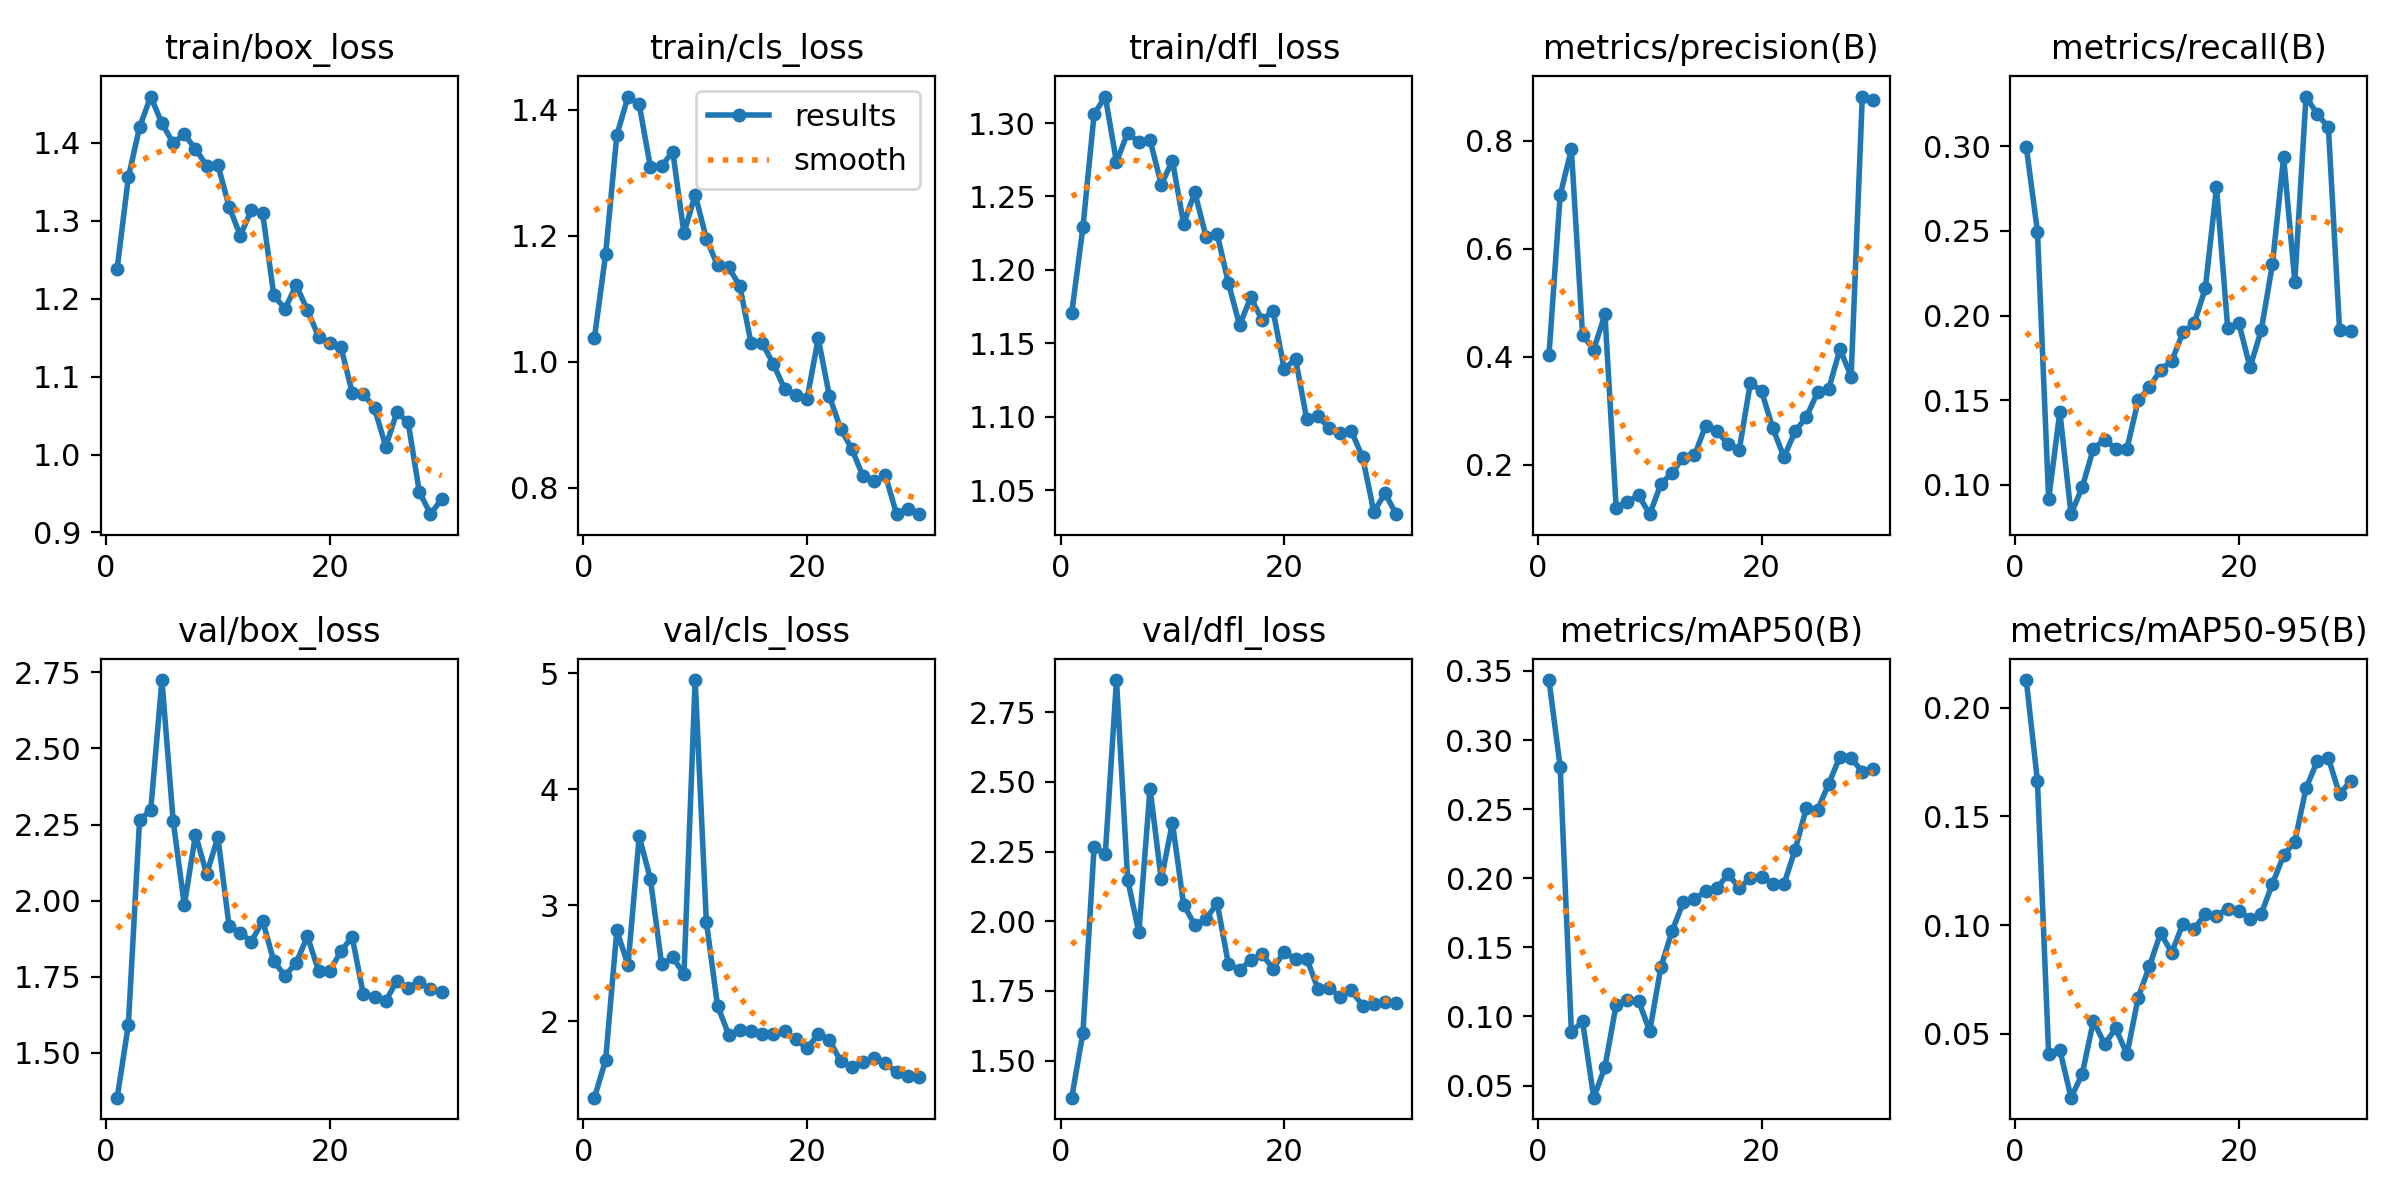


File penting E1:
results.png -> ADA
weights/best.pt -> ADA
weights/last.pt -> ADA


In [18]:

from IPython.display import display, Image
from pathlib import Path

folder = Path("/content/runs_yolo/E1_pretrained")

# Tampilkan grafik hasil pelatihan
grafik = folder / "results.png"

if grafik.exists():
    display(Image(filename=str(grafik), width=800))
else:
    print("Grafik results.png belum ditemukan.")

# Periksa file penting E1
print("\nFile penting E1:")
for nama in ["results.png", "weights/best.pt", "weights/last.pt"]:
    path = folder / nama
    print(nama, "->", "ADA" if path.exists() else "TIDAK ADA")


In [19]:

from ultralytics import YOLO

# Buat model YOLOv8n dari konfigurasi, tanpa bobot pretrained
model = YOLO("yolov8n.yaml")

hasil = model.train(
    data="/content/dataset_yolo_split/data.yaml",
    epochs=30,
    imgsz=640,
    batch=16,
    device=0,
    project="/content/runs_yolo",
    name="E2_scratch",
    seed=42,
    plots=True
)

print("Pelatihan E2 selesai!")
print("Folder hasil: /content/runs_yolo/E2_scratch")


Ultralytics 8.4.178 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/dataset_yolo_split/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.yaml, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=E2_scratch, nbs=64, nms=None, opset=None, optimiz

In [20]:

from ultralytics import YOLO

# Memulai dari model terbaik E1
model = YOLO("/content/runs_yolo/E1_pretrained/weights/best.pt")

hasil = model.train(
    data="/content/dataset_yolo_split/data.yaml",
    epochs=50,       # Perubahan: sebelumnya 30
    imgsz=640,
    batch=16,
    device=0,
    project="/content/runs_yolo",
    name="E3_finetuning",
    seed=42,
    plots=True
)

print("Pelatihan E3 selesai!")
print("Folder hasil: /content/runs_yolo/E3_finetuning")


Ultralytics 8.4.178 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/dataset_yolo_split/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/content/runs_yolo/E1_pretrained/weights/best.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=E3_finetuning

In [21]:

from ultralytics import YOLO

# Memuat model terbaik E1
model = YOLO("/content/runs_yolo/E1_pretrained/weights/best.pt")

# Evaluasi satu kali pada test set
hasil_test = model.val(
    data="/content/dataset_yolo_split/data.yaml",
    split="test",
    imgsz=640,
    batch=16,
    device=0,
    plots=True,
    project="/content/runs_yolo",
    name="E1_test"
)

print("Evaluasi test set selesai!")
print("Hasil tersimpan di /content/runs_yolo/E1_test")


Ultralytics 8.4.178 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,133,193 parameters, 0 gradients, 8.6 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.0±0.0 ms, read: 28.6±18.6 MB/s, size: 136.9 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/dataset_yolo_split/labels/test... 20 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 20/20 343.3it/s 0.1s
val: New cache created: /content/dataset_yolo_split/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 1.9it/s 1.0s
                   all         20         87      0.312      0.289      0.265       0.15
                person         20         80        0.7        0.7      0.722      0.418
                bottle          1          6      0.236      0.167     0.0631     0.0279
    

In [22]:

import os
import csv
import shutil
from google.colab import files

folder = "/content/runs_yolo"

# Ringkasan hasil ketiga percobaan
hasil = [
    ["E1_pretrained", 0.404, 0.300, 0.344, 0.213],
    ["E2_scratch",    0.712, 0.031, 0.0157, 0.00412],
    ["E3_finetuning", 0.428, 0.320, 0.383, 0.205],
]

# Simpan CSV
csv_path = "/content/hasil_praktik.csv"
with open(csv_path, "w", newline="", encoding="utf-8") as f:
    writer = csv.writer(f)
    writer.writerow([
        "Percobaan", "Precision", "Recall", "mAP50", "mAP50-95"
    ])
    writer.writerows(hasil)

# Simpan laporan TXT
txt_path = "/content/hasil_praktik.txt"
with open(txt_path, "w", encoding="utf-8") as f:
    f.write("LAPORAN PRAKTIK YOLO\n")
    f.write("====================\n\n")
    f.write("Dataset: 200 gambar COCO\n")
    f.write("Kelas: person, bottle, backpack\n")
    f.write("Pembagian: 140 train, 40 validation, 20 test\n\n")

    f.write("HASIL VALIDASI\n")
    f.write("E1 pretrained: Precision=0.404, Recall=0.300, ")
    f.write("mAP50=0.344, mAP50-95=0.213\n")
    f.write("E2 scratch: Precision=0.712, Recall=0.031, ")
    f.write("mAP50=0.0157, mAP50-95=0.00412\n")
    f.write("E3 fine-tuning: Precision=0.428, Recall=0.320, ")
    f.write("mAP50=0.383, mAP50-95=0.205\n\n")

    f.write("MODEL TERPILIH: E1 pretrained\n")
    f.write("Alasan: E1 memiliki mAP50-95 validasi tertinggi, ")
    f.write("yaitu 0.213.\n\n")

    f.write("HASIL TEST E1\n")
    f.write("Precision=0.312\n")
    f.write("Recall=0.289\n")
    f.write("mAP50=0.265\n")
    f.write("mAP50-95=0.150\n\n")

    f.write("ANALISIS\n")
    f.write("E1 unggul berdasarkan mAP50-95 validasi. ")
    f.write("E2 memiliki performa deteksi rendah karena dilatih dari awal ")
    f.write("menggunakan dataset yang terbatas. E3 memperoleh mAP50 ")
    f.write("tertinggi, tetapi mAP50-95-nya sedikit di bawah E1. ")
    f.write("Pada test set, kelas person terdeteksi lebih baik daripada ")
    f.write("bottle dan backpack. Jumlah contoh test untuk dua kelas ")
    f.write("terakhir sangat sedikit, sehingga hasilnya perlu ditafsirkan ")
    f.write("dengan hati-hati.\n")

print("File laporan berhasil dibuat.")
files.download(txt_path)
files.download(csv_path)


File laporan berhasil dibuat.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [23]:

from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [24]:

import os
import shutil

tujuan = "/content/drive/MyDrive/Tugas_YOLO"
os.makedirs(tujuan, exist_ok=True)

# Salin laporan
for nama in ["hasil_praktik.txt", "hasil_praktik.csv"]:
    sumber = f"/content/{nama}"
    if os.path.exists(sumber):
        shutil.copy2(sumber, tujuan)
        print("Tersimpan:", nama)
    else:
        print("Belum ditemukan:", nama)

# Salin grafik setiap percobaan
for percobaan in [
    "E1_pretrained",
    "E2_scratch",
    "E3_finetuning",
    "E1_test"
]:
    sumber = f"/content/runs_yolo/{percobaan}"
    if os.path.exists(sumber):
        shutil.copytree(
            sumber,
            f"{tujuan}/{percobaan}",
            dirs_exist_ok=True
        )
        print("Tersimpan:", percobaan)

# Salin konfigurasi dataset
yaml = "/content/dataset_yolo_split/data.yaml"
if os.path.exists(yaml):
    shutil.copy2(yaml, tujuan)
    print("Tersimpan: data.yaml")

print("\nSelesai! Folder tugas:", tujuan)


Tersimpan: hasil_praktik.txt
Tersimpan: hasil_praktik.csv
Tersimpan: E1_pretrained
Tersimpan: E2_scratch
Tersimpan: E3_finetuning
Tersimpan: E1_test
Tersimpan: data.yaml

Selesai! Folder tugas: /content/drive/MyDrive/Tugas_YOLO
